# Missing Data Analysis — Part 2A · Severity Analysis
## Stage 1 · Foundation, sanity tests and pilot run

**Author:** Purbasa Bhaduri · M.Sc. Statistics, St. Xavier's University, Kolkata

---

### What Part 2A is about
Part 1 compared seven missing-data methods on **one** dataset per mechanism at one fixed level of missingness. Part 2A turns that into a proper **Monte Carlo simulation study**: many datasets, missingness raised step by step from **10% to 50%**, three mechanisms (**MCAR, MAR, MNAR**), and performance measured by **bias, RMSE, 95% coverage and interval width** with Monte Carlo error.

Part 2A is delivered in two stages:

| Stage | Sections | What happens |
|---|---|---|
| **Stage 1 (this notebook)** | 1 – 7 | Build the simulation toolbox, test every piece, run a small **pilot**, time it, export everything as a zip |
| **Stage 2 (next)** | 8 – 12 | Full simulation (~1,000 replicates per condition), performance tables, severity figures |

### The study design (fixed protocol)
| Item | Choice |
|---|---|
| Data model | $Y = 5 + 2X_1 - 1.5X_2 + X_3 + \varepsilon,\ \varepsilon\sim N(0,1)$, $n = 100$, a **fresh dataset every replicate** |
| Severity | 10, 20, 30, 40, 50 % of $Y$ deleted — **exactly** that many values every time |
| Mechanisms | MCAR · MAR (depends on observed $X_1$) · MNAR (depends on hidden $Y$) + a *mild-MNAR* sensitivity run |
| Pairing | Inside a replicate, all mechanisms and severities start from the **same** complete dataset |
| Methods | Complete Case · Mean · Hot-Deck · Regression · Stochastic Regression · MICE (proper PMM, m = 20) · EM, plus a **Full Data** reference |
| Target | $\beta_1$ (true value 2); all four coefficients are stored |
| Inference | 200-resample bootstrap (all methods except MICE) · Rubin's rules (MICE) |

### How to use this notebook
1. *(Optional)* Upload `data_mcar.csv`, `data_mar.csv`, `data_mnar.csv` from Part 1 to the Colab file panel (left side) — Section 4.4 will then check that this new toolbox reproduces your Part 1 numbers. If you skip this, that check is skipped.
2. Run the cells **from top to bottom** (`Runtime → Run all` also works). Expected time: about **2–5 minutes**.
3. The last cell packs everything into **`part2A_stage1_outputs.zip`** and downloads it automatically.

> **Why a toolbox file?** The code of Sections 1–6 is written to a file called `sim_toolbox.py` and then imported. That keeps the notebook readable, makes the multi-core simulation reliable, and gives you a clean reusable module for your GitHub repo and for Stage 2.
> *If you ever re-run a single code cell that begins with `%%writefile`, re-run the notebook from Section 1 afterwards so the file stays clean.*

---
## Section 1 · Setup and protocol constants

### 1.1 Imports, folders and run settings
The only settings you may want to change are in the block marked **RUN SETTINGS**. The design itself (sample size, severity levels, mechanisms, methods) is the *protocol* and lives in the toolbox.

In [1]:
# 1.1  Imports, folders and run settings
import os, sys, time, json, shutil, platform, importlib, warnings, zipfile
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

# make the toolbox importable (also inside the parallel worker processes)
sys.dont_write_bytecode = True
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
os.environ["PYTHONPATH"] = os.getcwd() + os.pathsep + os.environ.get("PYTHONPATH", "")

# ------------------------- RUN SETTINGS (edit here only) -------------------------
R_PILOT      = 40                      # replicates in the pilot run (Stage 2 will use ~1000)
BOOT_B       = 200                     # bootstrap resamples per method per condition
R_CHECK      = 2000                    # replicates for the cheap missingness checks (Section 3)
N_JOBS       = os.cpu_count() or 1     # CPU cores to use
BRIDGE_CHECK = True                    # compare with Part 1 if you uploaded its CSV files (Section 4.4)
OUT          = "part2A_stage1_outputs" # everything saved here is zipped at the end
# ----------------------------------------------------------------------------------

for sub in ["figures", "results", "code"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# A logbook: every check in this notebook records PASS / FAIL here (summarised in Section 7)
TESTS = []
def record(section, check, passed, detail=""):
    TESTS.append({"section": section, "check": check,
                  "result": "PASS" if passed else "FAIL", "detail": detail})
    print(("PASS  " if passed else "FAIL  ") + f"[{section}] {check}" + (f"  ->  {detail}" if detail else ""))

def reload_toolbox():
    """Import (or re-import) the toolbox file that the %%writefile cells build."""
    importlib.invalidate_caches()
    import sim_toolbox
    return importlib.reload(sim_toolbox)

print("Python    :", platform.python_version())
print("numpy     :", np.__version__, "| pandas:", pd.__version__, "| scipy:", scipy.__version__,
      "| matplotlib:", matplotlib.__version__)
print("CPU cores :", N_JOBS)
print("Run date  :", time.strftime("%Y-%m-%d %H:%M"))

Python    : 3.13.16
numpy     : 2.1.3 | pandas: 2.2.3 | scipy: 1.16.3 | matplotlib: 3.10.0
CPU cores : 2
Run date  : 2026-10-11 15:57


### 1.2 Protocol constants — first part of the toolbox
This cell **creates** `sim_toolbox.py` and writes the fixed design constants into it (true coefficients, severity levels, mechanism definitions, method list, MICE/EM settings).

**The two selection strengths.** Under MAR the chance of losing $Y$ rises as $X_1$ falls; under MNAR it rises as $Y$ itself rises. In both cases, every extra standard deviation of the driver multiplies a row's deletion weight by $e^{\text{slope}}$. The main MNAR run uses slope **1.0**; the **mild** run uses **0.5**, which is the strength Part 1 used.

In [2]:
%%writefile sim_toolbox.py
"""
sim_toolbox.py  --  Part 2A simulation toolbox
Missing Data Analysis project  |  Author: Purbasa Bhaduri

Everything the Part 2A severity simulation needs, in one importable module:
data generator, missingness generators, seven missing-data methods + a full-data
reference, bootstrap / Rubin inference, a one-replicate engine and a metrics summary.

Design in one line: every replicate draws ONE complete dataset, deletes Y under every
mechanism and severity level, runs every method, and records the results in a tidy table.
"""
import numpy as np
import pandas as pd
from scipy import stats

# =====================================================================
# PROTOCOL CONSTANTS (the fixed design of Part 2A)
# =====================================================================
MASTER_SEED = 42                                   # same seed family as Part 1
N = 100                                            # sample size
BETA_TRUE = np.array([5.0, 2.0, -1.5, 1.0])        # beta0, beta1, beta2, beta3
TRUE = {"b0": 5.0, "b1": 2.0, "b2": -1.5, "b3": 1.0}
SIGMA = 1.0                                        # error SD
SEVERITY_LEVELS = [10, 20, 30, 40, 50]             # % of Y deleted

# Missingness mechanisms. "slope" = how strongly deletion depends on the driver
# (standardised X1 for MAR, standardised Y for MNAR). Every extra SD of the driver
# multiplies a row's deletion weight by exp(slope).
MECH_SPECS = {
    "MCAR":      {"kind": "mcar", "slope": 0.0},
    "MAR":       {"kind": "mar",  "slope": 1.0},    # low X1  -> more likely to lose Y
    "MNAR":      {"kind": "mnar", "slope": 1.0},    # high Y  -> more likely to lose Y  (main run)
    "MNAR_mild": {"kind": "mnar", "slope": 0.5},    # Part 1's strength (sensitivity run)
}
MAIN_MECHANISMS = ["MCAR", "MAR", "MNAR"]

METHODS = ["Complete Case", "Mean Imputation", "Hot-Deck", "Regression Imputation",
           "Stochastic Regression", "MICE", "EM"]
REFERENCE = "Full Data"                            # analysis of the data BEFORE deletion

MICE_M = 20                                        # number of imputations
PMM_K = 5                                          # PMM donor pool size
EM_TOL = 1e-8                                      # EM stopping rule (as in Part 1)
EM_MAXIT = 1000

Writing sim_toolbox.py


In [3]:
# 1.3  Load the toolbox and print the protocol
tb = reload_toolbox()

protocol = pd.DataFrame({
    "setting": ["sample size n", "true coefficients (b0, b1, b2, b3)", "error SD", "severity levels (% deleted)",
                "main mechanisms", "sensitivity mechanism", "methods", "reference", "MICE imputations (m)",
                "PMM donor pool (k)", "EM tolerance", "master seed"],
    "value": [tb.N, list(tb.BETA_TRUE), tb.SIGMA, tb.SEVERITY_LEVELS, ", ".join(tb.MAIN_MECHANISMS),
              "MNAR_mild (slope 0.5)", ", ".join(tb.METHODS), tb.REFERENCE, tb.MICE_M, tb.PMM_K,
              str(tb.EM_TOL), tb.MASTER_SEED]})
display(protocol)

,setting,value
0,sample size n,100
1,"true coefficients (b0, b1, b2, b3)","[5.0, 2.0, -1.5, 1.0]"
2,error SD,1.0
3,severity levels (% deleted),"[10, 20, 30, 40, 50]"
4,main mechanisms,"MCAR, MAR, MNAR"
5,sensitivity mechanism,MNAR_mild (slope 0.5)
6,methods,"Complete Case, Mean Imputation, Hot-Deck, Regr..."
7,reference,Full Data
8,MICE imputations (m),20
9,PMM donor pool (k),5


---
## Section 2 · Data generator

Every replicate starts by drawing a brand-new complete dataset from the Part 1 model. Three independent standard-normal predictors, normal noise with SD 1, and

$$Y = 5 + 2X_1 - 1.5X_2 + X_3 + \varepsilon .$$

**Reproducibility by design.** Each random stream is created from a tuple such as `(seed, replicate, purpose, …)`. So replicate 17 produces *exactly* the same data and results whether you use 1 core or 8, and whether it runs first or last. This is what makes the long Stage 2 run safe to split, resume and re-check.

In [4]:
%%writefile -a sim_toolbox.py

# =====================================================================
# SECTION 2 -- DATA GENERATOR
# =====================================================================
def make_rng(*keys):
    """Independent, reproducible random stream identified by a tuple of integers."""
    return np.random.default_rng(np.random.SeedSequence([int(k) for k in keys]))


def generate_complete_data(rng, n=N):
    """One complete dataset from  Y = 5 + 2*X1 - 1.5*X2 + X3 + e,  e ~ N(0, 1)."""
    X = rng.standard_normal((n, 3))
    eps = rng.normal(0.0, SIGMA, size=n)
    y = BETA_TRUE[0] + X @ BETA_TRUE[1:] + eps
    return X, y


def design(X):
    """Add the intercept column:  [1, X1, X2, X3]."""
    return np.column_stack([np.ones(len(X)), X])


# ---------- ordinary least squares helpers (used throughout) ----------
def ols_beta(Xd, y):
    """OLS coefficients (fast normal-equations solve, lstsq fallback)."""
    try:
        return np.linalg.solve(Xd.T @ Xd, Xd.T @ y)
    except np.linalg.LinAlgError:
        return np.linalg.lstsq(Xd, y, rcond=None)[0]


def ols(Xd, y):
    """OLS with covariance matrix. Returns beta, cov(beta), sigma2_hat, residuals."""
    beta = ols_beta(Xd, y)
    resid = y - Xd @ beta
    dfree = len(y) - Xd.shape[1]
    s2 = float(resid @ resid) / dfree
    cov = s2 * np.linalg.inv(Xd.T @ Xd)
    return beta, cov, s2, resid

Appending to sim_toolbox.py


In [5]:
# 2.2  Look at one generated dataset, and check the generator is unbiased
tb = reload_toolbox()

X, y = tb.generate_complete_data(tb.make_rng(tb.MASTER_SEED, 0, 0))
Xd = tb.design(X)
beta, cov, s2, resid = tb.ols(Xd, y)

print("First rows of replicate 0:")
display(pd.DataFrame(np.column_stack([X, y]), columns=["X1", "X2", "X3", "Y"]).head())
display(pd.DataFrame({"true": tb.BETA_TRUE, "OLS estimate": beta, "std. error": np.sqrt(np.diag(cov))},
                     index=["beta0", "beta1", "beta2", "beta3"]).round(3))

# average OLS over many generated datasets: should sit on the true values
B_ols = np.array([tb.ols_beta(tb.design(Xg), yg) for Xg, yg in
                  (tb.generate_complete_data(tb.make_rng(tb.MASTER_SEED, 5000 + r)) for r in range(2000))])
mean_b, se_b = B_ols.mean(axis=0), B_ols.std(axis=0, ddof=1) / np.sqrt(len(B_ols))
record("2", "Generator returns n = 100 rows with 3 predictors", X.shape == (100, 3) and len(y) == 100)
record("2", "OLS on complete data is unbiased for all four coefficients (2000 datasets)",
       bool(np.all(np.abs(mean_b - tb.BETA_TRUE) < 4 * se_b)),
       "mean estimates: " + ", ".join(f"{v:.3f}" for v in mean_b))

First rows of replicate 0:


,X1,X2,X3,Y
0,0.304717,-1.039984,0.750451,9.647212
1,0.940565,-1.951035,-1.302180,6.971641
2,0.127840,-0.316243,-0.016801,6.577072
3,-0.853044,0.879398,0.777792,2.424082
4,0.066031,1.127241,0.467509,3.847385


,true,OLS estimate,std. error
beta0,5.0,5.088,0.102
beta1,2.0,2.006,0.113
beta2,-1.5,-1.430,0.106
beta3,1.0,0.803,0.113


PASS  [2] Generator returns n = 100 rows with 3 predictors
PASS  [2] OLS on complete data is unbiased for all four coefficients (2000 datasets)  ->  mean estimates: 4.999, 2.001, -1.495, 1.002


---
## Section 3 · Missingness generators

This is the heart of the severity analysis, so it is built carefully.

### The three mechanisms
| Mechanism | Who loses $Y$? | Driver |
|---|---|---|
| **MCAR** | everyone equally likely | none — pure luck |
| **MAR** | rows with **low $X_1$** are more likely to lose $Y$ | $X_1$ (always observed) |
| **MNAR** | rows with **high $Y$** are more likely to lose $Y$ | $Y$ itself (the hidden value) |

### Three design improvements over Part 1
1. **Exact severity.** Part 1 flipped a biased coin per row, so the missing rate wandered (16%–25%). Here we delete **exactly** $k$ values ($k$ = 10, 20, 30, 40, 50), so "30% missing" always means 30%, for every mechanism. This removes the confounding between *mechanism* and *amount of missing data*.
2. **A selection score instead of a coin flip.** Each row gets a score = (driver term) + Gumbel noise, and the $k$ highest scores lose their $Y$. This is mathematically the same as drawing $k$ rows *without replacement* with probabilities proportional to $e^{\text{slope}\times\text{driver}}$ — so the selection pressure is controlled by one clear number.
3. **Nested deletion.** The same noise is reused across severity levels, so the 10% deleted set sits *inside* the 20% set, and so on. Differences between severity levels therefore reflect more missing data, not different luck — and the severity curves come out smoother.

The cell below writes the missingness generator into the toolbox.

In [6]:
%%writefile -a sim_toolbox.py

# =====================================================================
# SECTION 3 -- MISSINGNESS GENERATORS  (exact severity, three mechanisms)
# =====================================================================
def n_missing_for(level, n=N):
    """Number of Y values to delete for a severity level given in percent."""
    return int(round(n * level / 100.0))


def zscore(v):
    return (v - v.mean()) / v.std(ddof=1)


def draw_deletion_noise(rng, n=N):
    """Gumbel noise, one value per row. Shared by every mechanism and severity level
    inside a replicate (common random numbers), which makes the deleted sets NESTED:
    the 10% set sits inside the 20% set, and so on."""
    return rng.gumbel(size=n)


def selection_scores(X, y, mechanism, noise):
    """Score = driver term + Gumbel noise. The rows with the HIGHEST scores are deleted.
    Taking the top-k of (log-weight + Gumbel noise) is exactly sampling k rows without
    replacement with probabilities proportional to exp(log-weight)."""
    spec = MECH_SPECS[mechanism]
    if spec["kind"] == "mcar":
        eta = 0.0                                   # no driver: pure luck
    elif spec["kind"] == "mar":
        eta = -spec["slope"] * zscore(X[:, 0])      # depends on OBSERVED X1 (low X1 -> deleted)
    elif spec["kind"] == "mnar":
        eta = spec["slope"] * zscore(y)             # depends on the HIDDEN Y (high Y -> deleted)
    else:
        raise ValueError(mechanism)
    return eta + noise


def make_missing_mask(X, y, mechanism, n_missing, noise):
    """Boolean mask, True where Y is deleted. Exactly `n_missing` Trues."""
    mask = np.zeros(len(y), dtype=bool)
    if n_missing > 0:
        order = np.argsort(-selection_scores(X, y, mechanism, noise), kind="stable")
        mask[order[:n_missing]] = True
    return mask

Appending to sim_toolbox.py


### 3.2 One dataset, three mechanisms (30% missing)
Before any large check, look at a single dataset. The table compares the rows that **lost** their $Y$ with the rows that **kept** it. MCAR should show no real difference; MAR a clear difference in $X_1$; MNAR a clear difference in $Y$ (and, because $Y$ is correlated with the predictors, some difference in them too).

In [7]:
# 3.2  One dataset, three mechanisms at 30% missing
tb = reload_toolbox()
X, y = tb.generate_complete_data(tb.make_rng(tb.MASTER_SEED, 0, 0))
noise = tb.draw_deletion_noise(tb.make_rng(tb.MASTER_SEED, 0, 1))
k = tb.n_missing_for(30)

rows = []
for mech in tb.MECH_SPECS:
    m = tb.make_missing_mask(X, y, mech, k, noise)
    rows.append({"mechanism": mech, "Y deleted": int(m.sum()),
                 "mean X1 (deleted)": X[m, 0].mean(), "mean X1 (kept)": X[~m, 0].mean(),
                 "mean Y (deleted)": y[m].mean(), "mean Y (kept)": y[~m].mean()})
display(pd.DataFrame(rows).set_index("mechanism").round(3))

,Y deleted,mean X1 (deleted),mean X1 (kept),mean Y (deleted),mean Y (kept)
mechanism,,,,,
MCAR,30,0.116,-0.091,5.385,4.812
MAR,30,-0.493,0.170,4.149,5.342
MNAR,30,0.517,-0.263,6.867,4.177
MNAR_mild,30,0.352,-0.193,6.437,4.361


### 3.3 Large-scale verification of the generators
Now the same comparison over **`R_CHECK` = 2,000 datasets** and every mechanism × severity level. We check:

* the number of deleted values is **exactly** $k$ every time,
* deleted sets are **nested** as severity increases,
* **MCAR** shows no selection on $X_1$ or $Y$,
* **MAR** selects on $X_1$ (and not on $X_2$, a control),
* **MNAR** selects on $Y$.

The "gap" is *(mean of deleted rows − mean of kept rows) ÷ SD*, so it is in standard-deviation units.

In [8]:
# 3.3  Verify the generators over R_CHECK datasets
tb = reload_toolbox()
rng = tb.make_rng(tb.MASTER_SEED, 999)
counts_ok, nested_ok, recs = True, True, []

for r in range(R_CHECK):
    X, y = tb.generate_complete_data(rng)
    noise = tb.draw_deletion_noise(rng)
    for mech in tb.MECH_SPECS:
        prev = np.zeros(len(y), dtype=bool)
        for lvl in tb.SEVERITY_LEVELS:
            k = tb.n_missing_for(lvl)
            m = tb.make_missing_mask(X, y, mech, k, noise)
            counts_ok &= (m.sum() == k)
            nested_ok &= not np.any(prev & ~m)
            prev = m
            gap = lambda v: (v[m].mean() - v[~m].mean()) / v.std(ddof=1)
            recs.append((mech, lvl, gap(X[:, 0]), gap(X[:, 1]), gap(y)))

ver = (pd.DataFrame(recs, columns=["mechanism", "severity", "gap_X1", "gap_X2", "gap_Y"])
         .groupby(["mechanism", "severity"]).mean())
ver.round(3).to_csv(f"{OUT}/results/missingness_verification.csv")

print("Average standardised gaps (deleted minus kept), 2,000 datasets:")
display(ver.round(3).unstack(0)["gap_X1"].rename_axis(columns="gap in X1"))
display(ver.round(3).unstack(0)["gap_Y"].rename_axis(columns="gap in Y"))

record("3", "Exactly k values deleted in every dataset, mechanism and severity", bool(counts_ok))
record("3", "Deleted sets are nested across severity levels", bool(nested_ok))
record("3", "MCAR: no selection on X1 or Y (all gaps < 0.03 SD)",
       bool((ver.loc["MCAR"][["gap_X1", "gap_Y"]].abs() < 0.03).all().all()))
record("3", "MAR: deleted rows have clearly lower X1 (gap < -0.5), none on X2 (|gap| < 0.03)",
       bool((ver.loc["MAR"]["gap_X1"] < -0.5).all() and (ver.loc["MAR"]["gap_X2"].abs() < 0.03).all()))
record("3", "MNAR: deleted rows have clearly higher Y (gap > 0.5)", bool((ver.loc["MNAR"]["gap_Y"] > 0.5).all()))
record("3", "MNAR_mild is weaker than MNAR at every level",
       bool((ver.loc["MNAR_mild"]["gap_Y"] < ver.loc["MNAR"]["gap_Y"]).all()))

Average standardised gaps (deleted minus kept), 2,000 datasets:


gap in X1,MAR,MCAR,MNAR,MNAR_mild
severity,,,,
10,-0.981,0.002,0.679,0.357
20,-0.977,0.003,0.676,0.375
30,-0.984,-0.005,0.683,0.389
40,-1.001,-0.001,0.696,0.411
50,-1.036,-0.003,0.718,0.437


gap in Y,MAR,MCAR,MNAR,MNAR_mild
severity,,,,
10,-0.676,0.016,0.985,0.530
20,-0.677,0.007,0.977,0.545
30,-0.682,0.001,0.987,0.568
40,-0.694,0.002,1.005,0.595
50,-0.719,0.001,1.035,0.631


PASS  [3] Exactly k values deleted in every dataset, mechanism and severity
PASS  [3] Deleted sets are nested across severity levels
PASS  [3] MCAR: no selection on X1 or Y (all gaps < 0.03 SD)
PASS  [3] MAR: deleted rows have clearly lower X1 (gap < -0.5), none on X2 (|gap| < 0.03)
PASS  [3] MNAR: deleted rows have clearly higher Y (gap > 0.5)
PASS  [3] MNAR_mild is weaker than MNAR at every level


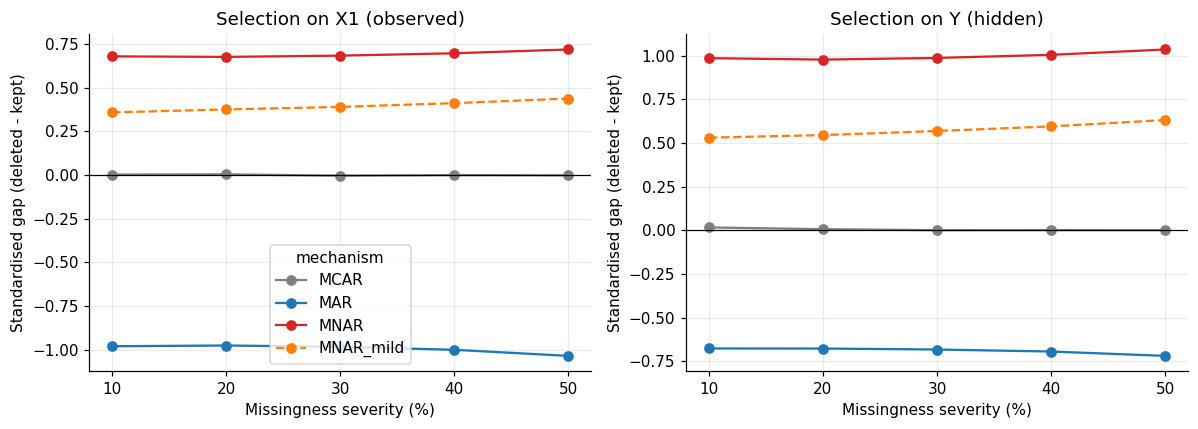

In [9]:
# 3.3b  Figure 1 - what each mechanism selects on
mech_style = {"MCAR": ("tab:gray", "-"), "MAR": ("tab:blue", "-"),
              "MNAR": ("tab:red", "-"), "MNAR_mild": ("tab:orange", "--")}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, ttl in zip(axes, ["gap_X1", "gap_Y"],
                        ["Selection on X1 (observed)", "Selection on Y (hidden)"]):
    for mech, (c, ls) in mech_style.items():
        s = ver.loc[mech, col]
        ax.plot(s.index, s.values, marker="o", color=c, ls=ls, label=mech)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Missingness severity (%)"); ax.set_ylabel("Standardised gap (deleted - kept)")
    ax.set_title(ttl); ax.set_xticks(tb.SEVERITY_LEVELS)
axes[0].legend(title="mechanism")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig1_missingness_verification.png", dpi=200); plt.show()

### 3.4 How strong is each mechanism? A quick preview with Complete Case
Before spending hours on the full simulation we should confirm the mechanisms actually *do something*. Complete Case regression is cheap, so we run it on 2,000 datasets for every mechanism and severity and look at its average bias in $\beta_1$ and in the intercept $\beta_0$.

**What theory predicts — and what you should see:**
* **MCAR** and **MAR** (depending only on the predictor $X_1$): Complete Case is **unbiased** (bias ≈ 0). Conditioning on $X$ in the regression absorbs MAR-on-$X$. This is *expected*, not a bug.
* **MNAR** (selection on $Y$ itself): bias appears and **grows with severity**. It shows most clearly in the **intercept** (high $Y$ values are deleted, so the fitted line sits too low), and as a smaller **attenuation of $\beta_1$**.

This is the cell where we judge whether the MNAR strength is sensible. Slope 1.0 should give a visible but not absurd distortion at 50%.

Complete Case: average bias of beta1 (2,000 datasets)


mechanism,MAR,MCAR,MNAR,MNAR_mild
severity,,,,
10,-0.001,-0.001,-0.023,-0.007
20,-0.001,0.000,-0.045,-0.013
30,-0.003,-0.000,-0.066,-0.021
40,-0.004,-0.002,-0.083,-0.030
50,-0.003,-0.003,-0.104,-0.040


Complete Case: average bias of beta0, the intercept


mechanism,MAR,MCAR,MNAR,MNAR_mild
severity,,,,
10,-0.004,-0.003,-0.039,-0.021
20,-0.004,-0.003,-0.083,-0.043
30,-0.003,-0.003,-0.131,-0.066
40,-0.001,-0.004,-0.183,-0.095
50,-0.002,-0.005,-0.251,-0.129


PASS  [3] Complete Case beta1 is unbiased under MCAR and MAR (|bias| < 4 MC SE, all levels)
PASS  [3] MNAR bias in beta1 is negative, significant and grows with severity  ->  bias at 10% = -0.023, at 50% = -0.104
PASS  [3] MNAR bias in the intercept is larger than in beta1 at 50%


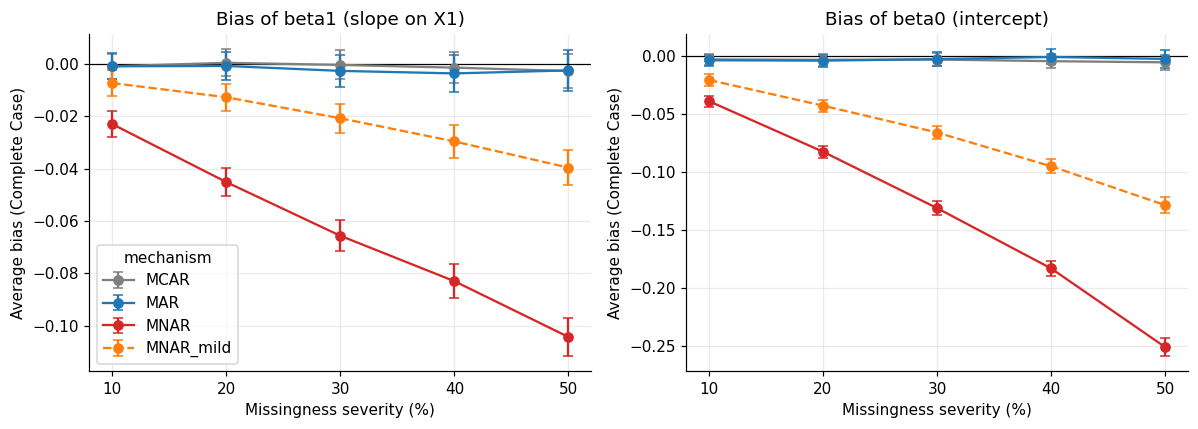

In [10]:
# 3.4  Complete Case preview: average bias by mechanism and severity
tb = reload_toolbox()
rng = tb.make_rng(tb.MASTER_SEED, 998)
recs = []
for r in range(R_CHECK):
    X, y = tb.generate_complete_data(rng)
    noise = tb.draw_deletion_noise(rng)
    Xd = tb.design(X)
    for mech in tb.MECH_SPECS:
        for lvl in tb.SEVERITY_LEVELS:
            m = tb.make_missing_mask(X, y, mech, tb.n_missing_for(lvl), noise)
            b = tb.ols_beta(Xd[~m], y[~m])
            recs.append((mech, lvl, b[0] - tb.TRUE["b0"], b[1] - tb.TRUE["b1"]))

raw_cc = pd.DataFrame(recs, columns=["mechanism", "severity", "bias_b0", "bias_b1"])
g = raw_cc.groupby(["mechanism", "severity"])
cc_prev = pd.concat([g.mean().add_suffix("_mean"), (g.std() / np.sqrt(R_CHECK)).add_suffix("_mcse")], axis=1)
cc_prev.round(4).to_csv(f"{OUT}/results/cc_strength_preview.csv")

print("Complete Case: average bias of beta1 (2,000 datasets)")
display(cc_prev["bias_b1_mean"].unstack(0).round(3))
print("Complete Case: average bias of beta0, the intercept")
display(cc_prev["bias_b0_mean"].unstack(0).round(3))

# checks: MCAR/MAR unbiased; MNAR clearly biased and growing
zs = (cc_prev["bias_b1_mean"] / cc_prev["bias_b1_mcse"]).unstack(0)
record("3", "Complete Case beta1 is unbiased under MCAR and MAR (|bias| < 4 MC SE, all levels)",
       bool((zs[["MCAR", "MAR"]].abs() < 4).all().all()))
b1_mnar = cc_prev["bias_b1_mean"].unstack(0)["MNAR"]
record("3", "MNAR bias in beta1 is negative, significant and grows with severity",
       bool((b1_mnar < 0).all() and (zs["MNAR"] < -3).all() and b1_mnar.is_monotonic_decreasing),
       f"bias at 10% = {b1_mnar.iloc[0]:.3f}, at 50% = {b1_mnar.iloc[-1]:.3f}")
record("3", "MNAR bias in the intercept is larger than in beta1 at 50%",
       bool(abs(cc_prev.loc[("MNAR", 50), "bias_b0_mean"]) > abs(cc_prev.loc[("MNAR", 50), "bias_b1_mean"])))

# Figure 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, ttl in zip(axes, ["bias_b1", "bias_b0"], ["Bias of beta1 (slope on X1)", "Bias of beta0 (intercept)"]):
    for mech, (c, ls) in mech_style.items():
        sub = cc_prev.loc[mech]
        ax.errorbar(sub.index, sub[col + "_mean"], yerr=2 * sub[col + "_mcse"], marker="o", capsize=3,
                    color=c, ls=ls, label=mech)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Missingness severity (%)"); ax.set_ylabel("Average bias (Complete Case)")
    ax.set_title(ttl); ax.set_xticks(tb.SEVERITY_LEVELS)
axes[0].legend(title="mechanism")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig2_complete_case_bias_preview.png", dpi=200); plt.show()

---
## Section 4 · Method toolbox and sanity tests

### The seven methods (plus a reference)
| # | Method | What it does | Randomness |
|---|---|---|---|
| ref | **Full Data** | OLS on the data *before* any deletion — the best any method could do | none |
| 1 | **Complete Case** | drop rows with missing $Y$, run OLS | none |
| 2 | **Mean Imputation** | fill every hole with the observed mean of $Y$ | none |
| 3 | **Hot-Deck** | copy the actual $Y$ of the nearest observed row (distance on $X_1,X_2,X_3$) | none |
| 4 | **Regression Imputation** | fill holes with predictions from $Y\sim X$ | none |
| 5 | **Stochastic Regression** | prediction + a residual resampled from the observed fit | yes |
| 6 | **MICE (PMM)** | 20 imputations by predictive mean matching, pooled by Rubin's rules | yes |
| 7 | **EM** | iterate expected sufficient statistics (E-step) and parameter updates (M-step) | none |

### What is new compared with Part 1
* **MICE is now *proper*.** For each imputation the regression parameters are first *drawn* from their posterior (including the variance), then donors are matched on the drawn prediction. Part 1's version re-used the fitted parameters, which understates uncertainty. We also use **m = 20** instead of 5.
* **Everything runs on one common interface** `method(Xd, y, rng) → coefficients`, so the same bootstrap engine judges every method by the same rules, and the whole simulation stays fast.
* **EM** is the same algorithm as Part 1 (start at $\beta=0$, stop when parameters move by less than $10^{-8}$), but also reports its iteration count.

The next cell adds all of this to the toolbox.

In [11]:
%%writefile -a sim_toolbox.py

# =====================================================================
# SECTION 4 -- METHOD TOOLBOX
# Every method takes (Xd, y, rng): Xd = design matrix WITH intercept, y = outcome with NaN
# for missing values. Single-imputation methods and EM return (beta_vector, extra).
# =====================================================================
# ---------- imputers: return a COMPLETED copy of y ----------
def impute_mean(Xd, y, rng=None):
    out = y.copy()
    miss = np.isnan(out)
    if miss.any():
        out[miss] = out[~miss].mean()
    return out


def impute_hotdeck(Xd, y, rng=None):
    """Deterministic nearest-donor hot-deck: copy the actual Y of the observed row whose
    (X1, X2, X3) is closest in squared Euclidean distance (same rule as Part 1)."""
    out = y.copy()
    miss = np.isnan(out)
    if not miss.any():
        return out
    obs = ~miss
    d2 = ((Xd[miss, 1:][:, None, :] - Xd[obs, 1:][None, :, :]) ** 2).sum(axis=2)
    out[miss] = y[obs][d2.argmin(axis=1)]
    return out


def impute_regression(Xd, y, rng=None):
    """Fit Y~X on observed rows, fill holes with the predictions (points on the plane)."""
    out = y.copy()
    miss = np.isnan(out)
    if not miss.any():
        return out
    beta = ols_beta(Xd[~miss], y[~miss])
    out[miss] = Xd[miss] @ beta
    return out


def impute_stochastic(Xd, y, rng):
    """Regression imputation + a residual resampled (with replacement) from the observed fit."""
    out = y.copy()
    miss = np.isnan(out)
    if not miss.any():
        return out
    beta = ols_beta(Xd[~miss], y[~miss])
    resid = y[~miss] - Xd[~miss] @ beta
    out[miss] = Xd[miss] @ beta + rng.choice(resid, size=int(miss.sum()), replace=True)
    return out


def pmm_complete(Xd, y, rng, k=PMM_K):
    """ONE proper PMM imputation (Rubin / van Buuren 'type-1' matching):
       1. fit Y~X on observed rows;  2. DRAW sigma^2 and beta from their posterior
       (this is what makes the imputation 'proper');  3. for each missing row, find the k
       observed rows whose fitted value is closest to the row's DRAWN prediction;
       4. copy the actual Y of one of those k donors, chosen at random."""
    out = y.copy()
    miss = np.isnan(out)
    n_mis = int(miss.sum())
    if n_mis == 0:
        return out
    obs = ~miss
    Xo, yo, Xm = Xd[obs], y[obs], Xd[miss]
    p = Xd.shape[1]
    beta_hat = ols_beta(Xo, yo)
    resid = yo - Xo @ beta_hat
    rss = float(resid @ resid)
    dfree = len(yo) - p
    L = np.linalg.cholesky(np.linalg.inv(Xo.T @ Xo))
    sigma_star = np.sqrt(rss / rng.chisquare(dfree))
    beta_star = beta_hat + sigma_star * (L @ rng.standard_normal(p))
    k_eff = min(k, len(yo))
    dist = np.abs((Xm @ beta_star)[:, None] - (Xo @ beta_hat)[None, :])
    nearest = np.argpartition(dist, k_eff - 1, axis=1)[:, :k_eff]
    pick = nearest[np.arange(n_mis), rng.integers(0, k_eff, size=n_mis)]
    out[miss] = yo[pick]
    return out


# ---------- EM for the normal linear model with Y missing ----------
def em_regression(Xd, y, tol=EM_TOL, max_iter=EM_MAXIT, return_path=False):
    """EM for  Y | X ~ N(X beta, sigma^2)  with missing Y (ignorable missingness).
       E-step: E[y_i] = x_i'beta,  E[y_i^2] = (x_i'beta)^2 + sigma^2   for missing rows.
       M-step: beta = (X'X)^-1 X' E[y],   sigma^2 = mean of E[(y_i - x_i'beta_new)^2].
       Starts from beta = 0, sigma^2 = 1; stops when no parameter moves by more than tol."""
    n, p = Xd.shape
    miss = np.isnan(y)
    obs = ~miss
    n_mis = int(miss.sum())
    P = np.linalg.solve(Xd.T @ Xd, Xd.T)
    beta = np.zeros(p)
    sigma2 = 1.0
    path = []
    n_iter = 0
    for it in range(1, max_iter + 1):
        mu = Xd @ beta
        y_exp = np.where(miss, mu, y)                              # E-step
        beta_new = P @ y_exp                                       # M-step (beta)
        fit_new = Xd @ beta_new
        r_obs = y[obs] - fit_new[obs]
        sigma2_new = (float(r_obs @ r_obs)
                      + float(((mu[miss] - fit_new[miss]) ** 2).sum()) + n_mis * sigma2) / n
        delta = max(np.max(np.abs(beta_new - beta)), abs(sigma2_new - sigma2))
        beta, sigma2, n_iter = beta_new, sigma2_new, it
        if return_path:
            path.append(beta.copy())
        if delta < tol:
            break
    if return_path:
        return beta, sigma2, n_iter, np.array(path)
    return beta, sigma2, n_iter


# ---------- the seven methods in the common (Xd, y, rng) -> (beta, extra) form ----------
def m_complete_case(Xd, y, rng=None):
    obs = ~np.isnan(y)
    return ols_beta(Xd[obs], y[obs]), None


def m_mean(Xd, y, rng=None):
    return ols_beta(Xd, impute_mean(Xd, y)), None


def m_hotdeck(Xd, y, rng=None):
    return ols_beta(Xd, impute_hotdeck(Xd, y)), None


def m_regression(Xd, y, rng=None):
    return ols_beta(Xd, impute_regression(Xd, y)), None


def m_stochastic(Xd, y, rng):
    return ols_beta(Xd, impute_stochastic(Xd, y, rng)), None


def m_em(Xd, y, rng=None):
    beta, sigma2, n_iter = em_regression(Xd, y)
    return beta, n_iter


# MICE is handled separately (it is pooled by Rubin's rules, not bootstrapped)
METHOD_FUNCS = {
    "Complete Case": m_complete_case,
    "Mean Imputation": m_mean,
    "Hot-Deck": m_hotdeck,
    "Regression Imputation": m_regression,
    "Stochastic Regression": m_stochastic,
    "EM": m_em,
}

Appending to sim_toolbox.py


### 4.2 All methods on one dataset (30% MCAR)
A quick look at what each method returns on the same incomplete dataset (MICE needs the pooling machinery of Section 5, so it joins in Section 5.4). Expect Complete Case = Regression Imputation = EM exactly, and Mean Imputation visibly dragging $\beta_1$ towards zero.

In [12]:
# 4.2  All methods on one incomplete dataset
tb = reload_toolbox()
X, y_full = tb.generate_complete_data(tb.make_rng(tb.MASTER_SEED, 0, 0))
Xd = tb.design(X)
noise = tb.draw_deletion_noise(tb.make_rng(tb.MASTER_SEED, 0, 1))
mask = tb.make_missing_mask(X, y_full, "MCAR", tb.n_missing_for(30), noise)
y = y_full.copy(); y[mask] = np.nan
print(f"Missing Y values: {int(np.isnan(y).sum())} of {len(y)}")

rows = {"TRUE VALUES": tb.BETA_TRUE, "Full Data (no deletion)": tb.ols_beta(Xd, y_full)}
for name, fn in tb.METHOD_FUNCS.items():
    rows[name] = fn(Xd, y, tb.make_rng(1, 2, 3))[0]
display(pd.DataFrame(rows, index=["b0", "b1", "b2", "b3"]).T.round(3))

Missing Y values: 30 of 100


,b0,b1,b2,b3
TRUE VALUES,5.000,2.000,-1.500,1.000
Full Data (no deletion),5.088,2.006,-1.430,0.803
Complete Case,5.073,2.114,-1.400,0.760
Mean Imputation,4.883,1.411,-1.019,0.542
Hot-Deck,5.060,1.937,-1.459,0.674
Regression Imputation,5.073,2.114,-1.400,0.760
Stochastic Regression,5.035,2.199,-1.465,0.792
EM,5.073,2.114,-1.400,0.760


### 4.3 Sanity tests
Each test below can only pass if the implementation is right. If any shows **FAIL**, stop and tell me — do not continue to the pilot.

| Test | Why it matters |
|---|---|
| No missing data → every method equals the full-data fit | catches bugs in every imputer and in EM at the boundary (MICE gets the same test in Section 5.3) |
| Regression Imputation = Complete Case = EM (many datasets, all conditions) | the known mathematical identity for "only $Y$ missing"; a failure means a bug |
| EM's variance equals the observed-case ML variance | EM converged to the right place |
| Imputed values are legitimate (observed donors, observed mean, residual set) | catches indexing mistakes in the donor-based methods |
| Mean imputation attenuates $\beta_1$ | the signature failure of mean imputation |
| Donor methods (PMM, Hot-Deck) become unbiased as $n$ grows | separates a genuine small-sample effect (expected at $n=100$) from a coding bug |

In [13]:
# 4.3  Sanity tests for the method toolbox
tb = reload_toolbox()

# --- (a) no missing data: every method must reproduce the full-data fit
X, y = tb.generate_complete_data(tb.make_rng(5))
Xd = tb.design(X)
full = tb.ols_beta(Xd, y)
worst = max(np.abs(fn(Xd, y, tb.make_rng(1))[0] - full).max() for fn in tb.METHOD_FUNCS.values())
record("4", "With 0% missing, all six single-imputation / EM methods equal the full-data OLS fit", worst < 1e-8, f"max diff {worst:.1e}")

# --- (b) Regression Imputation = Complete Case = EM, and (c) EM sigma^2 = observed-case ML variance
rng = tb.make_rng(tb.MASTER_SEED, 1001)
worst_beta, worst_s2, n_fits, em_conv = 0.0, 0.0, 0, True
for _ in range(30):
    X, y_full = tb.generate_complete_data(rng)
    noise = tb.draw_deletion_noise(rng)
    Xd = tb.design(X)
    for mech in tb.MECH_SPECS:
        for lvl in tb.SEVERITY_LEVELS:
            m = tb.make_missing_mask(X, y_full, mech, tb.n_missing_for(lvl), noise)
            y = y_full.copy(); y[m] = np.nan
            cc = tb.m_complete_case(Xd, y)[0]
            rg = tb.m_regression(Xd, y)[0]
            em, s2, n_it = tb.em_regression(Xd, y)
            res = y[~m] - Xd[~m] @ cc
            worst_beta = max(worst_beta, np.abs(cc - rg).max(), np.abs(cc - em).max())
            worst_s2 = max(worst_s2, abs(s2 - float(res @ res) / (~m).sum()))
            em_conv &= (n_it < tb.EM_MAXIT)
            n_fits += 1
record("4", f"Regression Imputation = Complete Case = EM ({n_fits} incomplete datasets)",
       worst_beta < 1e-6, f"max diff {worst_beta:.1e}")
record("4", "EM variance estimate equals the observed-case ML variance", worst_s2 < 1e-6, f"max diff {worst_s2:.1e}")
record("4", "EM converged (below the iteration cap) in every run", bool(em_conv))

# --- (d) imputed values are legitimate
rng = tb.make_rng(tb.MASTER_SEED, 1002)
X, y_full = tb.generate_complete_data(rng)
Xd = tb.design(X)
noise = tb.draw_deletion_noise(rng)
ok_mean = ok_hd = ok_pmm = ok_sr = True
for mech in tb.MAIN_MECHANISMS:
    m = tb.make_missing_mask(X, y_full, mech, tb.n_missing_for(30), noise)
    y = y_full.copy(); y[m] = np.nan
    y_obs = y[~m]
    ok_mean &= np.allclose(tb.impute_mean(Xd, y)[m], y_obs.mean())
    ok_hd   &= bool(np.isin(tb.impute_hotdeck(Xd, y)[m], y_obs).all())
    ok_pmm  &= bool(np.isin(tb.pmm_complete(Xd, y, tb.make_rng(7))[m], y_obs).all())
    b = tb.ols_beta(Xd[~m], y_obs)
    resid_set = y_obs - Xd[~m] @ b
    imputed = tb.impute_stochastic(Xd, y, tb.make_rng(8))[m] - Xd[m] @ b
    ok_sr &= bool(all(np.isclose(v, resid_set).any() for v in imputed))
record("4", "Mean imputation fills holes with the observed mean", bool(ok_mean))
record("4", "Hot-Deck and PMM imputations are actual observed Y values (donors)", bool(ok_hd and ok_pmm))
record("4", "Stochastic regression adds residuals drawn from the observed-fit residuals", bool(ok_sr))

# --- (e) mean imputation attenuates beta1
rng = tb.make_rng(tb.MASTER_SEED, 1003)
d_cc, d_mean = [], []
for _ in range(200):
    X, y_full = tb.generate_complete_data(rng)
    Xd = tb.design(X)
    m = tb.make_missing_mask(X, y_full, "MCAR", tb.n_missing_for(30), tb.draw_deletion_noise(rng))
    y = y_full.copy(); y[m] = np.nan
    d_cc.append(tb.m_complete_case(Xd, y)[0][1]); d_mean.append(tb.m_mean(Xd, y)[0][1])
record("4", "Mean imputation pulls beta1 towards 0 (30% MCAR, 200 datasets)",
       bool(np.mean(d_mean) < np.mean(d_cc) - 0.3),
       f"avg beta1: complete case {np.mean(d_cc):.3f}, mean imputation {np.mean(d_mean):.3f}")

# --- (f) PMM / hot-deck are consistent: their small-sample bias should melt away as n grows
def donor_bias(n, reps=40, seed_key=1004):
    out = {"pmm": [], "hotdeck": []}
    for r in range(reps):
        rng = tb.make_rng(tb.MASTER_SEED, seed_key, n, r)
        X, y_full = tb.generate_complete_data(rng, n)
        Xd = tb.design(X)
        m = tb.make_missing_mask(X, y_full, "MCAR", int(0.4 * n), tb.draw_deletion_noise(rng, n))
        y = y_full.copy(); y[m] = np.nan
        out["pmm"].append(np.mean([tb.ols_beta(Xd, tb.pmm_complete(Xd, y, rng))[1] for _ in range(5)]))
        out["hotdeck"].append(tb.m_hotdeck(Xd, y)[0][1])
    return {k: np.mean(v) - tb.TRUE["b1"] for k, v in out.items()}
small, large = donor_bias(100), donor_bias(1600)
record("4", "Donor-based methods are consistent: bias is small at n = 1600 (40% MCAR)",
       bool(abs(large["pmm"]) < 0.05 and abs(large["hotdeck"]) < 0.06),
       f"PMM bias: n=100 {small['pmm']:.3f} -> n=1600 {large['pmm']:.3f};  Hot-Deck: n=100 {small['hotdeck']:.3f} -> n=1600 {large['hotdeck']:.3f}")

PASS  [4] With 0% missing, all six single-imputation / EM methods equal the full-data OLS fit  ->  max diff 4.4e-16
PASS  [4] Regression Imputation = Complete Case = EM (600 incomplete datasets)  ->  max diff 6.6e-08
PASS  [4] EM variance estimate equals the observed-case ML variance  ->  max diff 6.2e-09
PASS  [4] EM converged (below the iteration cap) in every run
PASS  [4] Mean imputation fills holes with the observed mean
PASS  [4] Hot-Deck and PMM imputations are actual observed Y values (donors)
PASS  [4] Stochastic regression adds residuals drawn from the observed-fit residuals
PASS  [4] Mean imputation pulls beta1 towards 0 (30% MCAR, 200 datasets)  ->  avg beta1: complete case 1.995, mean imputation 1.385
PASS  [4] Donor-based methods are consistent: bias is small at n = 1600 (40% MCAR)  ->  PMM bias: n=100 -0.098 -> n=1600 -0.007;  Hot-Deck: n=100 -0.158 -> n=1600 -0.034


### 4.4 Bridge check: does the new toolbox reproduce Part 1? *(optional)*
This is the strongest validation available. If you uploaded your Part 1 files `data_mcar.csv`, `data_mar.csv`, `data_mnar.csv` (seed 42) into the Colab file panel, the cell below runs the **new** toolbox on those **same** datasets and compares the point estimates of $\beta_1$ with your Part 1 `master_results.csv`.
Complete Case, Mean, Hot-Deck, Regression and EM are fully deterministic, so they must match to many decimals. (Stochastic Regression and MICE are random, so they are not compared.)

*If the files are not there, the cell simply tells you so and moves on. You can upload them later and re-run only this cell.*

In [14]:
# 4.4  Optional bridge check against Part 1 (seed-42 datasets)
tb = reload_toolbox()
PART1_REF = {   # beta1 from Part 1 master_results.csv
    "MCAR": {"Complete Case": 1.7847226, "Mean Imputation": 1.0887497, "Hot-Deck": 1.6583060,
             "Regression Imputation": 1.7847226, "EM": 1.7847226},
    "MAR":  {"Complete Case": 1.7768965, "Mean Imputation": 1.3065739, "Hot-Deck": 1.7871541,
             "Regression Imputation": 1.7768965, "EM": 1.7768965},
    "MNAR": {"Complete Case": 1.7486858, "Mean Imputation": 1.4127452, "Hot-Deck": 1.7222066,
             "Regression Imputation": 1.7486858, "EM": 1.7486858},
}
files_ok = all(os.path.exists(f"data_{m.lower()}.csv") for m in PART1_REF)

if BRIDGE_CHECK and files_ok:
    recs = []
    for mech, ref in PART1_REF.items():
        d = pd.read_csv(f"data_{mech.lower()}.csv")
        Xd = tb.design(d[["X1", "X2", "X3"]].to_numpy()); yv = d["Y"].to_numpy()
        for meth, part1 in ref.items():
            new = tb.METHOD_FUNCS[meth](Xd, yv, tb.make_rng(1))[0][1]
            recs.append({"mechanism": mech, "method": meth, "Part 1": part1, "new toolbox": new,
                         "abs diff": abs(new - part1)})
    bridge = pd.DataFrame(recs)
    display(bridge.round(6))
    bridge.to_csv(f"{OUT}/results/bridge_check_vs_part1.csv", index=False)
    record("4", "New toolbox reproduces Part 1 beta1 for 5 deterministic methods x 3 mechanisms",
           bool(bridge["abs diff"].max() < 1e-5), f"max diff {bridge['abs diff'].max():.1e}")
else:
    print("Bridge check skipped: upload data_mcar.csv, data_mar.csv and data_mnar.csv to the Colab file "
          "panel (left side), then re-run this cell.")

,mechanism,method,Part 1,new toolbox,abs diff
0,MCAR,Complete Case,1.784723,1.784723,0.0
1,MCAR,Mean Imputation,1.088750,1.088750,0.0
2,MCAR,Hot-Deck,1.658306,1.658306,0.0
3,MCAR,Regression Imputation,1.784723,1.784723,0.0
4,MCAR,EM,1.784723,1.784723,0.0
5,MAR,Complete Case,1.776896,1.776896,0.0
6,MAR,Mean Imputation,1.306574,1.306574,0.0
7,MAR,Hot-Deck,1.787154,1.787154,0.0
8,MAR,Regression Imputation,1.776896,1.776896,0.0
9,MAR,EM,1.776896,1.776896,0.0


PASS  [4] New toolbox reproduces Part 1 beta1 for 5 deterministic methods x 3 mechanisms  ->  max diff 3.4e-08


### 4.5 EM convergence by severity
EM starts from $\beta = 0$ and walks to the maximum-likelihood solution. The more data are missing, the slower the walk (the convergence speed is governed by the *fraction of missing information*). This is useful to know for runtime planning and is worth a sentence in your write-up.

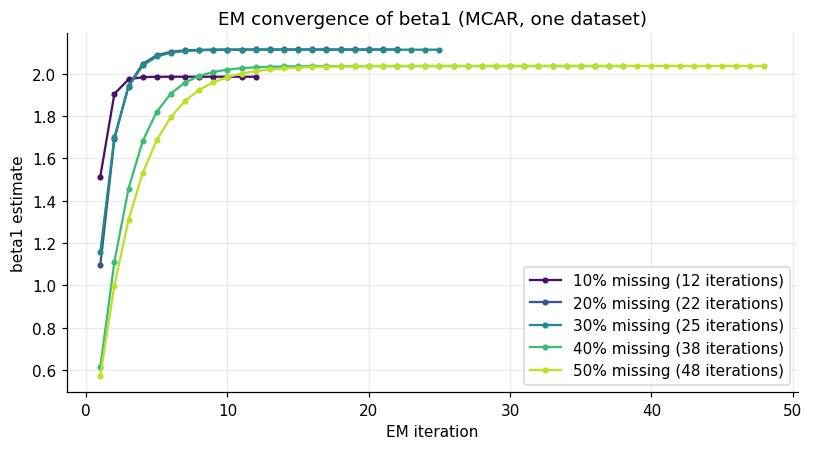

In [15]:
# 4.5  Figure 3 - EM convergence on one dataset
X, y_full = tb.generate_complete_data(tb.make_rng(tb.MASTER_SEED, 0, 0))
Xd = tb.design(X)
noise = tb.draw_deletion_noise(tb.make_rng(tb.MASTER_SEED, 0, 1))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for lvl, c in zip(tb.SEVERITY_LEVELS, plt.cm.viridis(np.linspace(0.05, 0.9, 5))):
    m = tb.make_missing_mask(X, y_full, "MCAR", tb.n_missing_for(lvl), noise)
    y = y_full.copy(); y[m] = np.nan
    beta, s2, n_it, path = tb.em_regression(Xd, y, return_path=True)
    ax.plot(range(1, n_it + 1), path[:, 1], marker="o", ms=3, color=c, label=f"{lvl}% missing ({n_it} iterations)")
ax.set_xlabel("EM iteration"); ax.set_ylabel("beta1 estimate"); ax.set_title("EM convergence of beta1 (MCAR, one dataset)")
ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig3_em_convergence_by_severity.png", dpi=200); plt.show()

---
## Section 5 · Inference functions

Every method must report not just an estimate but an **interval**, so that we can later measure *coverage* — the fraction of the time the 95% interval contains the true $\beta_1 = 2$.

### 5.1 The two inference engines
**Bootstrap (Complete Case, Mean, Hot-Deck, Regression, Stochastic Regression, EM).** Exactly the Part 1 scheme: resample **all** rows with replacement, re-run the **entire** method (imputation + regression) inside every resample, keep $\hat\beta_1$. SE = SD of the 200 values; the 95% interval = their 2.5th and 97.5th percentiles. *All methods share the same resamples inside a condition,* so differences between methods are not bootstrap luck.

**Rubin's rules (MICE).** With $m$ completed datasets giving $\hat\beta_1^{(j)}$ and variances $U^{(j)}$:

$$\bar Q=\tfrac1m\sum_j\hat\beta_1^{(j)},\quad W=\tfrac1m\sum_jU^{(j)},\quad B=\tfrac1{m-1}\sum_j(\hat\beta_1^{(j)}-\bar Q)^2,\quad T=W+\big(1+\tfrac1m\big)B,\quad SE=\sqrt T .$$

The interval is a $t$-interval. Part 1 used Rubin's *classical* degrees of freedom; with $n=100$ and $m=20$ that can be wildly larger than the sample itself, so Part 2 uses the **Barnard–Rubin small-sample adjustment** (the default in R's `mice`). The function can do both, and the test below checks the classical version against your Part 1 numbers.

### 5.2 Performance measures (used from Section 6 onwards)
| Measure | Meaning |
|---|---|
| **Bias** | average $\hat\beta_1 - 2$ |
| **Empirical SD** | spread of $\hat\beta_1$ across replicates (the *true* sampling variability) |
| **RMSE** | $\sqrt{\text{average}(\hat\beta_1-2)^2}$ — bias and variance together |
| **Average SE** | what the method *claims* its uncertainty is |
| **SE ratio** | average SE ÷ empirical SD — **1 means honest**; below 1 means over-confident |
| **Coverage** | share of 95% intervals containing 2 (target 95%) |
| **Width** | average interval length |

Each comes with its **Monte Carlo standard error**, so we always know how much of a difference is real.

In [16]:
%%writefile -a sim_toolbox.py

# =====================================================================
# SECTION 5 -- INFERENCE: Rubin's rules (MICE), bootstrap (everything else)
# =====================================================================
def rubin_pool(betas, variances, n_complete, n_params=4, df_method="barnard-rubin"):
    """Rubin's rules for every coefficient at once.
       betas, variances : arrays (m, p) of per-imputation estimates and their variances.
       df_method        : 'classical' (what Part 1 used) or 'barnard-rubin' (small-sample
                          adjusted, what R's mice uses; better with n = 100)."""
    betas = np.atleast_2d(betas)
    variances = np.atleast_2d(variances)
    m = betas.shape[0]
    qbar = betas.mean(axis=0)
    W = variances.mean(axis=0)
    B = betas.var(axis=0, ddof=1)
    T = W + (1.0 + 1.0 / m) * B
    lam = (1.0 + 1.0 / m) * B / T                       # fraction of variance due to missingness
    with np.errstate(divide="ignore", invalid="ignore"):
        df_old = (m - 1) / lam ** 2
        df_com = n_complete - n_params
        df_obs = (df_com + 1.0) / (df_com + 3.0) * df_com * (1.0 - lam)
        df_bar = df_old * df_obs / (df_old + df_obs)
    if df_method == "classical":
        df = df_old
    elif df_method == "barnard-rubin":
        df = np.where(lam > 0, df_bar, float(df_com))
    else:
        raise ValueError(df_method)
    return {"q": qbar, "se": np.sqrt(T), "df": df, "W": W, "B": B, "T": T, "lambda": lam}


def mice_pmm(Xd, y, rng, m=MICE_M, k=PMM_K, df_method="barnard-rubin"):
    """MICE with predictive mean matching: m proper PMM imputations, OLS on each completed
    dataset, pooled with Rubin's rules. (With only Y incomplete one cycle is enough -- there
    is nothing to iterate over -- so each imputation is a single proper PMM draw.)"""
    betas, variances = [], []
    for _ in range(m):
        yc = pmm_complete(Xd, y, rng, k=k)
        b, cov, _, _ = ols(Xd, yc)
        betas.append(b)
        variances.append(np.diag(cov))
    return rubin_pool(np.array(betas), np.array(variances), n_complete=len(y), df_method=df_method)


def bootstrap_beta1(method_fn, Xd, y, idx_matrix, rng, min_obs=10):
    """Part 1 bootstrap scheme: resample ALL rows with replacement, re-run the WHOLE method
    (imputation + regression) inside every resample, keep beta1.
    SE = SD of the draws; 95% CI = 2.5th / 97.5th percentiles."""
    draws = []
    for idx in idx_matrix:
        yb = y[idx]
        if np.isfinite(yb).sum() < min_obs:
            continue
        beta, _ = method_fn(Xd[idx], yb, rng)
        draws.append(beta[1])
    draws = np.asarray(draws)
    return (float(draws.std(ddof=1)), float(np.percentile(draws, 2.5)),
            float(np.percentile(draws, 97.5)), len(draws))


def summarise_results(res, coef="b1"):
    """Performance measures per (mechanism, severity, method), each with Monte Carlo error.
       bias, empirical SD, RMSE, mean estimated SE, SE ratio (calibration), 95% coverage
       and mean interval width."""
    truth = TRUE[coef]
    rows = []
    for (mech, sev, meth), g in res.groupby(["mechanism", "severity", "method"], sort=False):
        est = g[coef].to_numpy()
        R = len(est)
        err = est - truth
        bias = err.mean()
        sd = est.std(ddof=1) if R > 1 else np.nan
        rmse = np.sqrt((err ** 2).mean())
        avg_se = np.sqrt((g["se_b1"] ** 2).mean())
        covered = ((g["ci_lo"] <= truth) & (truth <= g["ci_hi"])).to_numpy()
        cov = covered.mean()
        mse_se = (err ** 2).std(ddof=1) / np.sqrt(R) if R > 1 else np.nan
        rows.append({
            "mechanism": mech, "severity": sev, "method": meth, "R": R,
            "bias": bias, "mc_se_bias": sd / np.sqrt(R) if R > 1 else np.nan,
            "emp_sd": sd, "rmse": rmse,
            "mc_se_rmse": mse_se / (2 * rmse) if rmse > 0 else np.nan,
            "avg_se": avg_se, "se_ratio": avg_se / sd if sd and sd > 0 else np.nan,
            "coverage": cov, "mc_se_cov": np.sqrt(cov * (1 - cov) / R),
            "width": float((g["ci_hi"] - g["ci_lo"]).mean()),
        })
    return pd.DataFrame(rows)

Appending to sim_toolbox.py


In [17]:
# 5.3  Tests for the inference functions
tb = reload_toolbox()

# (a) fast OLS agrees with statsmodels (if installed - it is on Colab)
X, y = tb.generate_complete_data(tb.make_rng(11))
Xd = tb.design(X)
b, cov, s2, resid = tb.ols(Xd, y)
try:
    import statsmodels.api as sm
    fit = sm.OLS(y, Xd).fit()
    record("5", "Own OLS coefficients and standard errors match statsmodels",
           bool(np.allclose(b, fit.params) and np.allclose(np.sqrt(np.diag(cov)), fit.bse)))
except ImportError:
    print("statsmodels not installed - comparison with statsmodels skipped")

# (b) Rubin's rules reproduce the Part 1 MICE-MCAR row (classical df)
betas = np.array([1.6787059323555065, 1.6452202132143983, 1.6079989640792878,
                  1.6407281146893147, 1.723652366471852]).reshape(-1, 1)
W_part1 = 0.010727030189071216
pool = tb.rubin_pool(betas, np.full_like(betas, W_part1), n_complete=100, df_method="classical")
record("5", "Rubin's rules reproduce Part 1 (pooled beta1 1.659261, SE 0.114170, df 127.60)",
       bool(abs(pool["q"][0] - 1.6592611) < 1e-6 and abs(pool["se"][0] - 0.1141703) < 1e-6
            and abs(pool["df"][0] - 127.6044) < 1e-3),
       f"got {pool['q'][0]:.6f}, {pool['se'][0]:.6f}, {pool['df'][0]:.3f}")

# (c) bootstrap SE for OLS on complete data is close to the textbook SE
idx = tb.make_rng(1, 2).integers(0, len(y), size=(500, len(y)))
se_boot, lo, hi, n_ok = tb.bootstrap_beta1(tb.m_complete_case, Xd, y, idx, None)
ratio = se_boot / np.sqrt(cov[1, 1])
record("5", "Bootstrap SE agrees with the analytic OLS SE on complete data (ratio within 0.85-1.15)",
       bool(0.85 < ratio < 1.15), f"ratio = {ratio:.3f}")

# (d) Barnard-Rubin df never exceeds the complete-data df
X, y_full = tb.generate_complete_data(tb.make_rng(tb.MASTER_SEED, 0, 0))
Xd = tb.design(X)
m = tb.make_missing_mask(X, y_full, "MCAR", tb.n_missing_for(30), tb.draw_deletion_noise(tb.make_rng(tb.MASTER_SEED, 0, 1)))
y = y_full.copy(); y[m] = np.nan
mice_out = tb.mice_pmm(Xd, y, tb.make_rng(3, 3, 3))
# (e) MICE with nothing missing must equal the full-data fit
X0, y0 = tb.generate_complete_data(tb.make_rng(5))
X0d = tb.design(X0)
diff0 = np.abs(tb.mice_pmm(X0d, y0, tb.make_rng(1))["q"] - tb.ols_beta(X0d, y0)).max()
record("5", "MICE with 0% missing equals the full-data OLS fit", diff0 < 1e-8, f"max diff {diff0:.1e}")

record("5", "Barnard-Rubin degrees of freedom are positive and at most n - p = 96",
       bool(np.all(mice_out["df"] > 0) and np.all(mice_out["df"] <= 96 + 1e-9)),
       f"df for beta1 = {mice_out['df'][1]:.1f}")

PASS  [5] Own OLS coefficients and standard errors match statsmodels
PASS  [5] Rubin's rules reproduce Part 1 (pooled beta1 1.659261, SE 0.114170, df 127.60)  ->  got 1.659261, 0.114170, 127.604
PASS  [5] Bootstrap SE agrees with the analytic OLS SE on complete data (ratio within 0.85-1.15)  ->  ratio = 1.093
PASS  [5] MICE with 0% missing equals the full-data OLS fit  ->  max diff 8.9e-16
PASS  [5] Barnard-Rubin degrees of freedom are positive and at most n - p = 96  ->  df for beta1 = 47.0


### 5.4 MICE on one dataset, step by step
This shows the whole Rubin machinery on the same 30%-MCAR dataset: the 20 separate estimates, the within-imputation variance $W$, the between-imputation variance $B$, the fraction of variance due to missingness $\lambda$, and the resulting interval.

In [18]:
# 5.4  Anatomy of one MICE run
yc_betas = []
rng_m = tb.make_rng(3, 3, 3)
for _ in range(tb.MICE_M):
    yc = tb.pmm_complete(Xd, y, rng_m)
    yc_betas.append(tb.ols_beta(Xd, yc)[1])
yc_betas = np.array(yc_betas)

q, s, d = mice_out["q"][1], mice_out["se"][1], mice_out["df"][1]
tc = tb.stats.t.ppf(0.975, d)
anatomy = pd.Series({
    "number of imputations m": tb.MICE_M,
    "range of the 20 estimates of beta1": f"{yc_betas.min():.3f} to {yc_betas.max():.3f}",
    "pooled estimate (Q-bar)": q,
    "within variance W": mice_out["W"][1],
    "between variance B": mice_out["B"][1],
    "lambda (share of variance from missingness)": mice_out["lambda"][1],
    "pooled SE = sqrt(T)": s,
    "Barnard-Rubin df": d,
    "95% interval": f"({q - tc * s:.3f}, {q + tc * s:.3f})",
})
display(anatomy.to_frame("value"))

,value
number of imputations m,20
range of the 20 estimates of beta1,1.956 to 2.291
pooled estimate (Q-bar),2.075144
within variance W,0.014454
between variance B,0.006622
lambda (share of variance from missingness),0.324807
pooled SE = sqrt(T),0.14631
Barnard-Rubin df,46.951929
95% interval,"(1.781, 2.369)"


---
## Section 6 · Pilot run

The toolbox is complete. Now we tie everything together in a **one-replicate engine** and test it at small scale before committing to the full run.

### 6.1 The replicate engine
For each replicate the engine:

1. draws one complete dataset;
2. runs **Full Data** (the reference);
3. for **each of 3 mechanisms × 5 severity levels** deletes $Y$, then runs **all 7 methods** with bootstrap or Rubin inference;
4. returns one tidy row per (mechanism, severity, method): the four coefficients, SE of $\beta_1$, interval limits, EM iteration count and MICE degrees of freedom.

That is **106 rows per replicate** (1 reference + 3 × 5 × 7).

In [19]:
%%writefile -a sim_toolbox.py

# =====================================================================
# SECTION 6 -- ONE-REPLICATE ENGINE
# =====================================================================
def _row(rep, mech, sev, nmiss, method, beta, se1, lo, hi, em_iters=np.nan, mice_df=np.nan):
    return {"rep": rep, "mechanism": mech, "severity": sev, "n_missing": nmiss, "method": method,
            "b0": beta[0], "b1": beta[1], "b2": beta[2], "b3": beta[3],
            "se_b1": se1, "ci_lo": lo, "ci_hi": hi, "em_iters": em_iters, "mice_df": mice_df}


def run_replicate(rep, mechanisms=MAIN_MECHANISMS, levels=SEVERITY_LEVELS, boot_B=200,
                  mice_m=MICE_M, master_seed=MASTER_SEED, n=N):
    """One full replicate: draw a complete dataset, then for every mechanism x severity level
    delete Y, run every method and record the estimates. Returns a list of row-dicts.

    Reproducibility: every random stream is identified by (seed, replicate, purpose, ...), so a
    replicate gives identical output however many cores are used or in which order they run."""
    X, y_full = generate_complete_data(make_rng(master_seed, rep, 0), n)
    Xd = design(X)
    noise = draw_deletion_noise(make_rng(master_seed, rep, 1), n)
    p = Xd.shape[1]
    rows = []

    # reference: analysis of the complete data (analytic t-interval)
    beta, cov, _, _ = ols(Xd, y_full)
    se = np.sqrt(np.diag(cov))
    tcrit = stats.t.ppf(0.975, n - p)
    rows.append(_row(rep, "NONE", 0, 0, REFERENCE, beta, se[1],
                     beta[1] - tcrit * se[1], beta[1] + tcrit * se[1]))

    spec_names = list(MECH_SPECS)
    for mech in mechanisms:
        for li, level in enumerate(levels):
            k = n_missing_for(level, n)
            mask = make_missing_mask(X, y_full, mech, k, noise)
            y = y_full.copy()
            y[mask] = np.nan
            cid = spec_names.index(mech) * 100 + li               # condition id
            idx_matrix = make_rng(master_seed, rep, 2, cid).integers(0, n, size=(boot_B, n))
            for mi, meth in enumerate(METHODS):
                if meth == "MICE":
                    out = mice_pmm(Xd, y, make_rng(master_seed, rep, 3, cid, mi), m=mice_m)
                    q, s, d = out["q"], out["se"][1], out["df"][1]
                    tc = stats.t.ppf(0.975, d)
                    rows.append(_row(rep, mech, level, k, meth, q, s, q[1] - tc * s, q[1] + tc * s,
                                     mice_df=d))
                else:
                    fn = METHOD_FUNCS[meth]
                    beta, extra = fn(Xd, y, make_rng(master_seed, rep, 3, cid, mi))
                    se1, lo, hi, _ = bootstrap_beta1(fn, Xd, y, idx_matrix,
                                                     make_rng(master_seed, rep, 4, cid, mi))
                    rows.append(_row(rep, mech, level, k, meth, beta, se1, lo, hi,
                                     em_iters=(extra if meth == "EM" else np.nan)))
    return rows

Appending to sim_toolbox.py


### 6.2 Timing and a reproducibility test
We run 2 replicates **one after the other** on a single core. This tells us two things: how long one replicate takes (so we can plan Stage 2), and a reference result that the parallel pilot below must reproduce **exactly**.

In [20]:
# 6.2  Timing: two replicates, sequentially
tb = reload_toolbox()
t0 = time.time()
seq_rows = [tb.run_replicate(r, boot_B=BOOT_B) for r in range(2)]
sec_per_rep = (time.time() - t0) / 2

plan = pd.DataFrame({"replicates R": [500, 1000, 2000]})
plan["est. minutes (this machine)"] = (sec_per_rep * plan["replicates R"] / N_JOBS / 60).round(1)
plan["est. hours"] = (plan["est. minutes (this machine)"] / 60).round(2)
print(f"Seconds per replicate on one core: {sec_per_rep:.2f}   (bootstrap B = {BOOT_B}, {N_JOBS} core(s) available)")
print("Rough projection for the full run (assumes near-linear speed-up across cores):")
display(plan)

Seconds per replicate on one core: 3.98   (bootstrap B = 200, 2 core(s) available)
Rough projection for the full run (assumes near-linear speed-up across cores):


,replicates R,est. minutes (this machine),est. hours
0,500,16.6,0.28
1,1000,33.2,0.55
2,2000,66.3,1.10


### 6.3 Run the pilot
`R_PILOT` replicates spread over all available cores. Progress messages are printed by the parallel engine.

In [21]:
# 6.3  Pilot run (parallel)
from joblib import Parallel, delayed

t0 = time.time()
rows_list = Parallel(n_jobs=N_JOBS, verbose=5)(
    delayed(tb.run_replicate)(r, boot_B=BOOT_B) for r in range(R_PILOT))
pilot = pd.DataFrame([row for rows in rows_list for row in rows])
pilot_seconds = time.time() - t0

pilot.to_csv(f"{OUT}/results/pilot_results.csv", index=False)
print(f"\nPilot finished: {R_PILOT} replicates in {pilot_seconds:.0f} s  ->  {pilot.shape[0]} rows x {pilot.shape[1]} columns")
display(pilot.head(8).round(3))

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:  1.3min



Pilot finished: 40 replicates in 185 s  ->  4240 rows x 14 columns


[Parallel(n_jobs=2)]: Done  40 out of  40 | elapsed:  3.1min finished


,rep,mechanism,severity,n_missing,method,b0,b1,b2,b3,se_b1,ci_lo,ci_hi,em_iters,mice_df
0,0,NONE,0,0,Full Data,5.088,2.006,-1.430,0.803,0.113,1.782,2.230,NaN,NaN
1,0,MCAR,10,10,Complete Case,5.061,1.986,-1.460,0.832,0.118,1.779,2.197,NaN,NaN
2,0,MCAR,10,10,Mean Imputation,4.939,1.776,-1.371,0.759,0.135,1.518,2.032,NaN,NaN
3,0,MCAR,10,10,Hot-Deck,5.030,1.908,-1.464,0.752,0.119,1.695,2.140,NaN,NaN
4,0,MCAR,10,10,Regression Imputation,5.061,1.986,-1.460,0.832,0.118,1.779,2.197,NaN,NaN
5,0,MCAR,10,10,Stochastic Regression,5.082,2.014,-1.486,0.934,0.122,1.749,2.210,NaN,NaN
6,0,MCAR,10,10,MICE,5.043,1.968,-1.453,0.820,0.122,1.725,2.212,NaN,83.045
7,0,MCAR,10,10,EM,5.061,1.986,-1.460,0.832,0.118,1.779,2.197,12.0,NaN


### 6.4 Pilot integrity checks
These verify that the engine's output is complete, sensible and **reproducible**.

In [22]:
# 6.4  Integrity checks on the pilot output
n_methods, n_mech, n_lvl = len(tb.METHODS), len(tb.MAIN_MECHANISMS), len(tb.SEVERITY_LEVELS)
expected_rows = R_PILOT * (1 + n_mech * n_lvl * n_methods)
num_cols = ["b0", "b1", "b2", "b3", "se_b1", "ci_lo", "ci_hi"]

record("6", f"Row count = {R_PILOT} replicates x 106 rows", len(pilot) == expected_rows, f"{len(pilot)} rows")
record("6", "No missing values in estimates, SEs or interval limits", bool(pilot[num_cols].notna().all().all()))
record("6", "Every interval has positive width and every SE is positive",
       bool((pilot["ci_hi"] > pilot["ci_lo"]).all() and (pilot["se_b1"] > 0).all()))
record("6", "n_missing equals the severity level in every row (exact deletion)",
       bool((pilot.query("mechanism != 'NONE'")["n_missing"] == pilot.query("mechanism != 'NONE'")["severity"]).all()))

wide = pilot.pivot_table(index=["rep", "mechanism", "severity"], columns="method", values=["b0", "b1", "b2", "b3"])
diff_rce = max((wide[c]["Regression Imputation"] - wide[c]["Complete Case"]).abs().max() for c in ["b0", "b1", "b2", "b3"])
diff_em = max((wide[c]["EM"] - wide[c]["Complete Case"]).abs().max() for c in ["b0", "b1", "b2", "b3"])
record("6", "In the pilot: Regression Imputation = Complete Case = EM (all coefficients)",
       bool(max(diff_rce, diff_em) < 1e-6), f"max diff {max(diff_rce, diff_em):.1e}")

seq = pd.DataFrame([row for rows in seq_rows for row in rows])
par = pilot[pilot["rep"].isin([0, 1])].reset_index(drop=True)
record("6", "Parallel run reproduces the sequential run exactly (replicates 0 and 1)", bool(seq.equals(par)))

mice_df = pilot.loc[pilot["method"] == "MICE", "mice_df"]
record("6", "MICE degrees of freedom are finite and positive", bool(np.isfinite(mice_df).all() and (mice_df > 0).all()))
em_it = pilot.loc[pilot["method"] == "EM", "em_iters"]
record("6", "EM converged below the iteration cap in every run", bool((em_it < tb.EM_MAXIT).all()),
       f"max iterations = {int(em_it.max())}")

PASS  [6] Row count = 40 replicates x 106 rows  ->  4240 rows
PASS  [6] No missing values in estimates, SEs or interval limits
PASS  [6] Every interval has positive width and every SE is positive
PASS  [6] n_missing equals the severity level in every row (exact deletion)
PASS  [6] In the pilot: Regression Imputation = Complete Case = EM (all coefficients)  ->  max diff 6.4e-08
PASS  [6] Parallel run reproduces the sequential run exactly (replicates 0 and 1)
PASS  [6] MICE degrees of freedom are finite and positive
PASS  [6] EM converged below the iteration cap in every run  ->  max iterations = 129


### 6.5 First look at the pilot results
**Read these as a smoke test, not as findings.** With only `R_PILOT` replicates the averages are noisy, and coverage figures cannot be trusted — that is exactly what Stage 2 is for. What we *can* check now is that the broad patterns match theory:

* Mean Imputation should sit clearly below the others and get worse as severity grows.
* Complete Case, Regression Imputation and EM should be identical to each other.
* MNAR should start to pull estimates down at high severity.

In [23]:
# 6.5  Pilot preview tables: average bias of beta1
summ = tb.summarise_results(pilot)
summ.to_csv(f"{OUT}/results/pilot_summary.csv", index=False)

for mech in tb.MAIN_MECHANISMS:
    tab = (summ[summ["mechanism"] == mech]
           .pivot(index="method", columns="severity", values="bias").reindex(tb.METHODS))
    print(f"\n{mech}: average bias of beta1 by severity (pilot, R = {R_PILOT})")
    display(tab.round(3))

print("\nEM iterations needed (average over pilot replicates):")
display(pilot[pilot["method"] == "EM"].groupby("severity")["em_iters"].mean().round(1).to_frame("avg iterations").T)


MCAR: average bias of beta1 by severity (pilot, R = 40)


severity,10,20,30,40,50
method,,,,,
Complete Case,-0.017,-0.018,-0.034,-0.038,-0.033
Mean Imputation,-0.224,-0.415,-0.621,-0.840,-1.038
Hot-Deck,-0.051,-0.079,-0.133,-0.181,-0.236
Regression Imputation,-0.017,-0.018,-0.034,-0.038,-0.033
Stochastic Regression,-0.022,-0.009,-0.032,-0.037,-0.051
MICE,-0.038,-0.053,-0.090,-0.129,-0.172
EM,-0.017,-0.018,-0.034,-0.038,-0.033



MAR: average bias of beta1 by severity (pilot, R = 40)


severity,10,20,30,40,50
method,,,,,
Complete Case,-0.028,-0.019,-0.013,-0.019,-0.026
Mean Imputation,-0.355,-0.643,-0.892,-1.132,-1.363
Hot-Deck,-0.099,-0.173,-0.276,-0.379,-0.544
Regression Imputation,-0.028,-0.019,-0.013,-0.019,-0.026
Stochastic Regression,-0.025,-0.010,-0.006,-0.033,-0.010
MICE,-0.064,-0.090,-0.140,-0.222,-0.330
EM,-0.028,-0.019,-0.013,-0.019,-0.026



MNAR: average bias of beta1 by severity (pilot, R = 40)


severity,10,20,30,40,50
method,,,,,
Complete Case,-0.041,-0.066,-0.092,-0.122,-0.151
Mean Imputation,-0.382,-0.666,-0.911,-1.138,-1.364
Hot-Deck,-0.112,-0.213,-0.307,-0.450,-0.591
Regression Imputation,-0.041,-0.066,-0.092,-0.122,-0.151
Stochastic Regression,-0.042,-0.068,-0.090,-0.130,-0.150
MICE,-0.090,-0.177,-0.261,-0.396,-0.549
EM,-0.041,-0.066,-0.092,-0.122,-0.151



EM iterations needed (average over pilot replicates):


severity,10,20,30,40,50
avg iterations,14.4,21.7,30.8,43.6,65.3


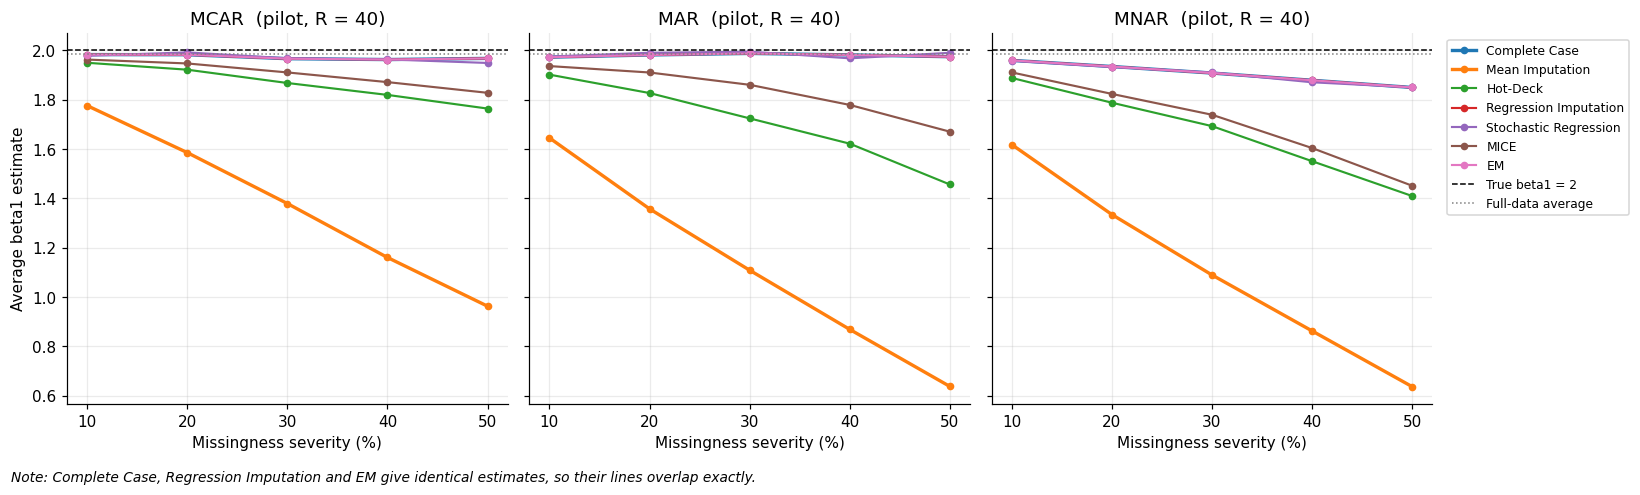

In [24]:
# 6.6  Figure 4 - pilot: average beta1 by method and severity
colors = dict(zip(tb.METHODS, plt.cm.tab10(np.arange(7))))
full_mean = pilot.loc[pilot["method"] == tb.REFERENCE, "b1"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, mech in zip(axes, tb.MAIN_MECHANISMS):
    for meth in tb.METHODS:
        s = summ[(summ["mechanism"] == mech) & (summ["method"] == meth)].set_index("severity")["bias"] + tb.TRUE["b1"]
        ax.plot(s.index, s.values, marker="o", ms=4, color=colors[meth], label=meth,
                lw=2.2 if meth in ("Complete Case", "Mean Imputation") else 1.4)
    ax.axhline(tb.TRUE["b1"], color="k", ls="--", lw=1, label="True beta1 = 2")
    ax.axhline(full_mean, color="gray", ls=":", lw=1, label="Full-data average")
    ax.set_title(f"{mech}  (pilot, R = {R_PILOT})"); ax.set_xlabel("Missingness severity (%)")
    ax.set_xticks(tb.SEVERITY_LEVELS)
axes[0].set_ylabel("Average beta1 estimate")
fig.text(0.01, -0.03, "Note: Complete Case, Regression Imputation and EM give identical estimates, so their lines overlap exactly.",
         fontsize=9, style="italic")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/fig4_pilot_beta1_by_severity.png", dpi=200, bbox_inches="tight"); plt.show()

In [25]:
# 6.7  Pilot-based sanity of the expected patterns
at50 = summ[summ["severity"] == 50].pivot(index="method", columns="mechanism", values="bias")
record("6", "Mean imputation has the largest bias at 50% under every mechanism",
       bool((at50.abs().idxmax() == "Mean Imputation").all()))
mean_curve = summ[(summ["method"] == "Mean Imputation") & (summ["mechanism"] == "MCAR")].set_index("severity")["bias"]
record("6", "Mean imputation bias worsens as MCAR severity grows (10% -> 50%)",
       bool(mean_curve.loc[50] < mean_curve.loc[10]), f"{mean_curve.loc[10]:.3f} -> {mean_curve.loc[50]:.3f}")

PASS  [6] Mean imputation has the largest bias at 50% under every mechanism
PASS  [6] Mean imputation bias worsens as MCAR severity grows (10% -> 50%)  ->  -0.224 -> -1.038


---
## Section 7 · Stage 1 report card and export

### 7.1 Report card
Every check from the whole notebook, in one table. **All rows should say PASS.**

In [26]:
# 7.1  Report card
report = pd.DataFrame(TESTS)
report.to_csv(f"{OUT}/results/sanity_tests.csv", index=False)
pd.set_option("display.max_colwidth", 120, "display.width", 220)
display(report)

n_pass, n_fail = int((report["result"] == "PASS").sum()), int((report["result"] == "FAIL").sum())
print(f"\n{n_pass} checks passed, {n_fail} failed.")
print("STAGE 1 STATUS: READY FOR STAGE 2" if n_fail == 0 else "STAGE 1 STATUS: PLEASE REVIEW THE FAILED CHECKS")

,section,check,result,detail
0,2,Generator returns n = 100 rows with 3 predictors,PASS,
1,2,OLS on complete data is unbiased for all four coefficients (2000 datasets),PASS,"mean estimates: 4.999, 2.001, -1.495, 1.002"
2,3,"Exactly k values deleted in every dataset, mechanism and severity",PASS,
3,3,Deleted sets are nested across severity levels,PASS,
4,3,MCAR: no selection on X1 or Y (all gaps < 0.03 SD),PASS,
5,3,"MAR: deleted rows have clearly lower X1 (gap < -0.5), none on X2 (|gap| < 0.03)",PASS,
6,3,MNAR: deleted rows have clearly higher Y (gap > 0.5),PASS,
7,3,MNAR_mild is weaker than MNAR at every level,PASS,
8,3,"Complete Case beta1 is unbiased under MCAR and MAR (|bias| < 4 MC SE, all levels)",PASS,
9,3,"MNAR bias in beta1 is negative, significant and grows with severity",PASS,"bias at 10% = -0.023, at 50% = -0.104"



36 checks passed, 0 failed.
STAGE 1 STATUS: READY FOR STAGE 2


### 7.2 Package everything and download
This cell saves the toolbox, your run settings and a short README into the output folder, zips it as **`part2A_stage1_outputs.zip`** and starts the download. (In Colab the download begins automatically; if your browser blocks it, open the folder icon on the left and download the zip from there.)

**What is inside the zip**
| Folder | Contents |
|---|---|
| `code/` | `sim_toolbox.py` — the complete, tested toolbox (also a good file for your GitHub repo) |
| `results/` | report card, missingness verification, Complete Case preview, bridge check (if run), pilot results and pilot summary |
| `figures/` | Figures 1–4 (PNG, 200 dpi) |
| top level | `README_stage1.txt`, `config_and_environment.json` |

In [27]:
# 7.2  Export: toolbox, config, README -> zip -> download
shutil.copy("sim_toolbox.py", f"{OUT}/code/sim_toolbox.py")

config = {
    "stage": "Part 2A - Stage 1",
    "run_date": time.strftime("%Y-%m-%d %H:%M"),
    "master_seed": tb.MASTER_SEED, "n": tb.N, "true_beta": list(tb.BETA_TRUE),
    "severity_levels": tb.SEVERITY_LEVELS, "mechanisms": tb.MECH_SPECS,
    "methods": tb.METHODS, "mice_m": tb.MICE_M, "pmm_k": tb.PMM_K,
    "run_settings": {"R_PILOT": R_PILOT, "BOOT_B": BOOT_B, "R_CHECK": R_CHECK, "N_JOBS": N_JOBS},
    "timing": {"seconds_per_replicate_one_core": round(sec_per_rep, 3), "pilot_seconds": round(pilot_seconds, 1)},
    "checks": {"passed": n_pass, "failed": n_fail},
    "environment": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
}
with open(f"{OUT}/config_and_environment.json", "w") as f:
    json.dump(config, f, indent=2, default=str)

readme = f"""MISSING DATA ANALYSIS - PART 2A (SEVERITY ANALYSIS) - STAGE 1 OUTPUTS
Author: Purbasa Bhaduri
Run date: {config['run_date']}

Contents
  code/sim_toolbox.py                       tested simulation toolbox (import it in Stage 2)
  results/sanity_tests.csv                  report card: {n_pass} passed, {n_fail} failed
  results/missingness_verification.csv      standardised gaps by mechanism and severity ({R_CHECK} datasets)
  results/cc_strength_preview.csv           Complete Case bias preview ({R_CHECK} datasets)
  results/bridge_check_vs_part1.csv         comparison with Part 1 (only if Part 1 CSVs were uploaded)
  results/pilot_results.csv                 raw pilot output, {R_PILOT} replicates, one row per replicate x condition x method
  results/pilot_summary.csv                 pilot performance measures (noisy - smoke test only)
  figures/fig1..fig4                        verification, Complete Case preview, EM convergence, pilot beta1
  config_and_environment.json               settings, timing and software versions

Design: n=100, Y = 5 + 2*X1 - 1.5*X2 + X3 + e; severity 10-50% (exact counts); MCAR, MAR, MNAR
(+ MNAR_mild); 7 methods + full-data reference; bootstrap B={BOOT_B}; MICE m={tb.MICE_M} (proper PMM, Rubin).
Timing: {sec_per_rep:.2f} s per replicate on one core.
"""
with open(f"{OUT}/README_stage1.txt", "w") as f:
    f.write(readme)

zip_path = shutil.make_archive(OUT, "zip", root_dir=".", base_dir=OUT)
print("Created:", zip_path, f"({os.path.getsize(zip_path) / 1024:.0f} KB)\n")
with zipfile.ZipFile(zip_path) as z:
    for info in z.infolist():
        print(f"  {info.filename:60s} {info.file_size / 1024:8.1f} KB")

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("\n(Not running in Colab - the zip is in the current folder.)")

Created: /content/part2A_stage1_outputs.zip (836 KB)

  part2A_stage1_outputs/                                            0.0 KB
  part2A_stage1_outputs/code/                                       0.0 KB
  part2A_stage1_outputs/figures/                                    0.0 KB
  part2A_stage1_outputs/results/                                    0.0 KB
  part2A_stage1_outputs/config_and_environment.json                 1.0 KB
  part2A_stage1_outputs/README_stage1.txt                           1.2 KB
  part2A_stage1_outputs/code/sim_toolbox.py                        17.5 KB
  part2A_stage1_outputs/figures/fig4_pilot_beta1_by_severity.png    231.0 KB
  part2A_stage1_outputs/figures/fig3_em_convergence_by_severity.png    117.5 KB
  part2A_stage1_outputs/figures/fig1_missingness_verification.png    116.5 KB
  part2A_stage1_outputs/figures/fig2_complete_case_bias_preview.png    153.7 KB
  part2A_stage1_outputs/results/sanity_tests.csv                    3.0 KB
  part2A_stage1_outputs/results

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## What to do next
1. Check that Section 7.1 says **READY FOR STAGE 2** and the downloaded zip opens.
2. Come back and tell me: **(a)** whether every check passed, **(b)** the timing table from Section 6.2, and **(c)** anything that looked odd. You can also upload the zip so I can look at the pilot output and figures.
3. From the timing I will set the final replicate count and bootstrap size, and write **Stage 2**: the full simulation with automatic checkpoints, the performance tables with Monte Carlo errors, and the severity figures.